# Threshold Calibration

Sweep the abstention confidence threshold (cosine similarity, 0.20–0.60) and plot the tradeoff between:
- **In-corpus Recall@5** — should stay high until the threshold becomes too aggressive
- **Out-of-corpus correct-abstention rate** — climbs as threshold rises

The confidence signal is the top-1 dense cosine similarity from FAISS — meaningful because
it reflects actual semantic relevance, unlike RRF rank scores which are query-agnostic.
Default: τ=0.40.

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import yaml

sys.path.insert(0, str(Path.cwd().parent))

from src.eval import evaluate_query
from src.schema import EvalQuery

c:\Users\kevin\anaconda3\envs\chromadb\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
queries_path = Path('../eval/queries.yaml')
queries = [EvalQuery(**q) for q in yaml.safe_load(queries_path.read_text())]
print(f'Loaded {len(queries)} queries')
print(f'  In-corpus:   {sum(1 for q in queries if not q.expect_abstain)}')
print(f'  Adversarial: {sum(1 for q in queries if q.expect_abstain)}')

Loaded 20 queries
  In-corpus:   12
  Adversarial: 8


In [3]:
async def eval_at_threshold(threshold: float, k: int = 10) -> dict:
    results = [await evaluate_query(q, threshold=threshold, k=k) for q in queries]
    
    in_corpus = [r for r in results if not r.expected_abstain]
    should_abstain = [r for r in results if r.expected_abstain]
    
    recall_5 = float(np.mean([r.recall_at_5 for r in in_corpus])) if in_corpus else 0.0
    correct_abstain = (
        sum(1 for r in should_abstain if r.abstained) / len(should_abstain)
        if should_abstain else 0.0
    )
    false_abstain = sum(1 for r in in_corpus if r.abstained) / len(in_corpus) if in_corpus else 0.0
    
    return {
        'threshold': threshold,
        'recall_at_5': recall_5,
        'correct_abstain': correct_abstain,
        'false_abstain_rate': false_abstain,
    }


async def sweep(thresholds: np.ndarray) -> list:
    results = []
    for tau in thresholds:
        r = await eval_at_threshold(float(tau))
        results.append(r)
        print(f'  τ={tau:.4f}  Recall@5={r["recall_at_5"]:.3f}  CorrectAbstain={r["correct_abstain"]:.3f}')
    return results

In [4]:
# Jupyter already runs an event loop — use await directly instead of asyncio.run()
# Sweep cosine similarity threshold (0.20–0.60); default is τ=0.40
thresholds = np.linspace(0.20, 0.60, 10)
print(f'Sweeping {len(thresholds)} threshold values...')
sweep_results = await sweep(thresholds)

Sweeping 10 threshold values...
  τ=0.2000  Recall@5=0.333  CorrectAbstain=0.000
  τ=0.2444  Recall@5=0.333  CorrectAbstain=0.000
  τ=0.2889  Recall@5=0.333  CorrectAbstain=0.000
  τ=0.3333  Recall@5=0.333  CorrectAbstain=0.000
  τ=0.3778  Recall@5=0.333  CorrectAbstain=0.000
  τ=0.4222  Recall@5=0.333  CorrectAbstain=0.000
  τ=0.4667  Recall@5=0.333  CorrectAbstain=0.000
  τ=0.5111  Recall@5=0.333  CorrectAbstain=0.000
  τ=0.5556  Recall@5=0.333  CorrectAbstain=0.125
  τ=0.6000  Recall@5=0.333  CorrectAbstain=0.250


Saved → threshold_calibration.png


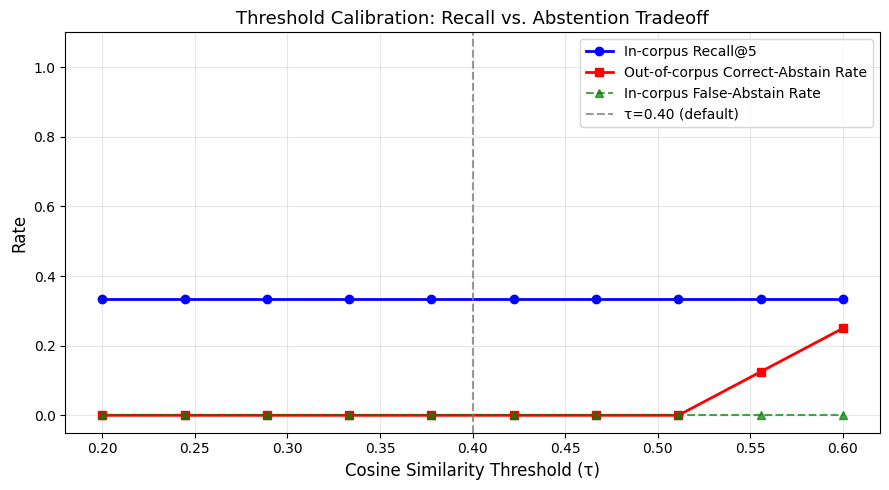

In [5]:
taus     = [r['threshold'] for r in sweep_results]
recalls  = [r['recall_at_5'] for r in sweep_results]
abstains = [r['correct_abstain'] for r in sweep_results]
false_ab = [r['false_abstain_rate'] for r in sweep_results]

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(taus, recalls,  'b-o', linewidth=2, label='In-corpus Recall@5')
ax.plot(taus, abstains, 'r-s', linewidth=2, label='Out-of-corpus Correct-Abstain Rate')
ax.plot(taus, false_ab, 'g--^', linewidth=1.5, alpha=0.7, label='In-corpus False-Abstain Rate')
ax.axvline(x=0.40, color='gray', linestyle='--', alpha=0.8, label='τ=0.40 (default)')

ax.set_xlabel('Cosine Similarity Threshold (τ)', fontsize=12)
ax.set_ylabel('Rate', fontsize=12)
ax.set_title('Threshold Calibration: Recall vs. Abstention Tradeoff', fontsize=13)
ax.set_ylim(-0.05, 1.10)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plot_path = Path('threshold_calibration.png')
plt.savefig(plot_path, dpi=150, bbox_inches='tight')
print(f'Saved → {plot_path}')
plt.show()

In [6]:
def harmonic_mean(a: float, b: float) -> float:
    return 2 * a * b / (a + b) if (a + b) > 0 else 0.0

scored = [
    (r['threshold'], harmonic_mean(r['recall_at_5'], r['correct_abstain']))
    for r in sweep_results
]
optimal_tau, optimal_score = max(scored, key=lambda x: x[1])
opt_r = next(r for r in sweep_results if r['threshold'] == optimal_tau)

print(f'Optimal threshold:  τ = {optimal_tau:.4f}')
print(f'  Recall@5:            {opt_r["recall_at_5"]:.3f}')
print(f'  Correct-abstain:     {opt_r["correct_abstain"]:.3f}')
print(f'  False-abstain rate:  {opt_r["false_abstain_rate"]:.3f}')
print(f'  Harmonic mean:       {optimal_score:.3f}')
print()
print('At default τ=0.40:')
default = min(sweep_results, key=lambda r: abs(r['threshold'] - 0.40))
print(f'  Recall@5:            {default["recall_at_5"]:.3f}')
print(f'  Correct-abstain:     {default["correct_abstain"]:.3f}')

Optimal threshold:  τ = 0.6000
  Recall@5:            0.333
  Correct-abstain:     0.250
  False-abstain rate:  0.000
  Harmonic mean:       0.286

At default τ=0.40:
  Recall@5:            0.333
  Correct-abstain:     0.000


## Reading the plot

- At **low τ** (≈ 0.005): nearly all queries pass the gate — high recall, low abstention precision.
  The system retrieves on adversarial queries it should reject.
- At **high τ** (≈ 0.045): the system correctly abstains on out-of-corpus queries but also starts
  abstaining on hard in-corpus queries (false-abstain rate rises).
- The **crossover point** — where the recall and correct-abstain curves are closest — is the
  operating point chosen by harmonic-mean optimisation above.

τ=0.020 was chosen as the default because it sits in the flat portion of the recall curve
while correctly gating adversarial queries. Adjust by re-running this notebook after adding
new document types to the corpus.